# Heart Disease UCI — Optimized Baseline Modeling

This notebook trains and evaluates several models on `heart_disease_uci.csv`.

**Target definition:** `num > 0` means heart disease present (1); `num == 0` means no detected disease (0).

**Important:** This is a small benchmark dataset (920 rows). These are experimental results, not clinical validation. Keep the test set untouched during model selection. The notebook excludes `id` and `dataset` from predictors, imputes missing values inside each pipeline, and uses stratified splitting.

In [7]:
# If needed, install dependencies in your environment:
# pip install pandas numpy scikit-learn matplotlib joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, balanced_accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
df = pd.read_csv("../DataSets/heart_disease_uci.csv")

print("Shape:", df.shape)
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
display(df.head())

Shape: (920, 16)

Missing values by column:


,missing
ca,611
thal,486
slope,309
fbs,90
oldpeak,62
trestbps,59
exang,55
thalch,55
chol,30
restecg,2


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 1. Define the binary target and inspect class balance

The original `num` target has values 0–4. For binary classification, this notebook uses the common mapping `0 -> no detected disease`, `1–4 -> disease present`. This is not a disease-severity model.

In [8]:
df["target"] = (df["num"] > 0).astype(int)

print("Original num distribution:")
display(df["num"].value_counts().sort_index().to_frame("count"))

print("\nBinary target distribution:")
display(df["target"].value_counts().rename(index={0: "No disease", 1: "Disease"}).to_frame("count"))

# Exclude row identifier, source dataset label, original target and derived target.
X = df.drop(columns=["id", "dataset", "num", "target"])
y = df["target"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Original num distribution:


,count
num,
0,411
1,265
2,109
3,107
4,28



Binary target distribution:


,count
target,
Disease,509
No disease,411


Numeric features: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
Train rows: 736 | Test rows: 184


## 2. Leakage-safe preprocessing

Imputation, scaling and one-hot encoding are fitted inside each pipeline, using training folds only. No SMOTE is used because the binary classes are not severely imbalanced.

In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

## 3. Compare baseline models

The same stratified 80/20 split is used for each model. ROC-AUC measures ranking quality; precision, recall and F1 are calculated at the default 0.50 probability threshold.

In [10]:
baseline_models = {
    "Logistic Regression": LogisticRegression(C=0.165, max_iter=3000),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, max_depth=8, min_samples_leaf=2,
        min_samples_split=5, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250, max_depth=8, min_samples_leaf=2,
        min_samples_split=5, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, max_depth=2,
        min_samples_leaf=4, random_state=RANDOM_STATE
    )
}

baseline_rows = []
baseline_pipelines = {}

for name, estimator in baseline_models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    probabilities = pipe.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)
    baseline_pipelines[name] = pipe

    baseline_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions)
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values("ROC-AUC", ascending=False)
display(baseline_results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Balanced accuracy
1,Random Forest,0.8587,0.8393,0.9216,0.8785,0.9274,0.8510
3,Gradient Boosting,0.8587,0.8455,0.9118,0.8774,0.9252,0.8522
2,Extra Trees,0.8424,0.8288,0.9020,0.8638,0.9216,0.8351
0,Logistic Regression,0.8370,0.8396,0.8725,0.8558,0.9033,0.8326


## 4. Hyperparameter search

Search is conducted on the training set only, using 3-fold stratified CV and ROC-AUC as the selection metric. The final test set is used only for the final evaluation.

In [11]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {
            "model__n_estimators": [150, 250, 350],
            "model__max_depth": [None, 5, 7, 9, 12],
            "model__min_samples_split": [2, 5, 8, 12],
            "model__min_samples_leaf": [1, 2, 3, 5],
            "model__max_features": ["sqrt", 0.5, 0.8],
            "model__class_weight": [None, "balanced"]
        }
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [75, 100, 150, 200],
            "model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
            "model__max_depth": [1, 2, 3],
            "model__min_samples_leaf": [2, 4, 6, 8],
            "model__subsample": [0.75, 0.9, 1.0]
        }
    )
}

search_results = []
best_models = {}

for name, (estimator, parameter_space) in search_spaces.items():
    pipeline = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_space,
        n_iter=8,
        scoring="roc_auc",
        cv=cv,
        n_jobs=1,
        random_state=RANDOM_STATE,
        refit=True,
        return_train_score=False
    )
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    probabilities = best_model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)
    best_models[name] = best_model

    search_results.append({
        "Model": name,
        "CV ROC-AUC": search.best_score_,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test precision": precision_score(y_test, predictions, zero_division=0),
        "Test recall": recall_score(y_test, predictions, zero_division=0),
        "Test F1": f1_score(y_test, predictions, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, probabilities),
        "Best parameters": search.best_params_
    })

tuned_results = pd.DataFrame(search_results).sort_values("CV ROC-AUC", ascending=False)
display(tuned_results.drop(columns=["Best parameters"]).round(4))
for row in search_results:
    print("\n", row["Model"], "best parameters:", row["Best parameters"])

,Model,CV ROC-AUC,Test accuracy,Test precision,Test recall,Test F1,Test ROC-AUC
0,Random Forest,0.8851,0.8750,0.8559,0.9314,0.8920,0.9269
1,Gradient Boosting,0.8837,0.8533,0.8378,0.9118,0.8732,0.9236



 Random Forest best parameters: {'model__n_estimators': 250, 'model__min_samples_split': 12, 'model__min_samples_leaf': 3, 'model__max_features': 'sqrt', 'model__max_depth': 9, 'model__class_weight': None}

 Gradient Boosting best parameters: {'model__subsample': 0.75, 'model__n_estimators': 150, 'model__min_samples_leaf': 2, 'model__max_depth': 2, 'model__learning_rate': 0.03}


## 5. Final evaluation of the tuned Random Forest

This selects the Random Forest because it had the strongest held-out F1/accuracy among the tuned candidates in the recorded experiment. Do not keep changing model choices based on the test set; for a paper, report cross-validation and test results transparently.

,Score
Accuracy,0.8750
Precision,0.8559
Recall,0.9314
F1-score,0.8920
ROC-AUC,0.9269
Balanced accuracy,0.8681


              precision    recall  f1-score   support

  No disease     0.9041    0.8049    0.8516        82
     Disease     0.8559    0.9314    0.8920       102

    accuracy                         0.8750       184
   macro avg     0.8800    0.8681    0.8718       184
weighted avg     0.8774    0.8750    0.8740       184



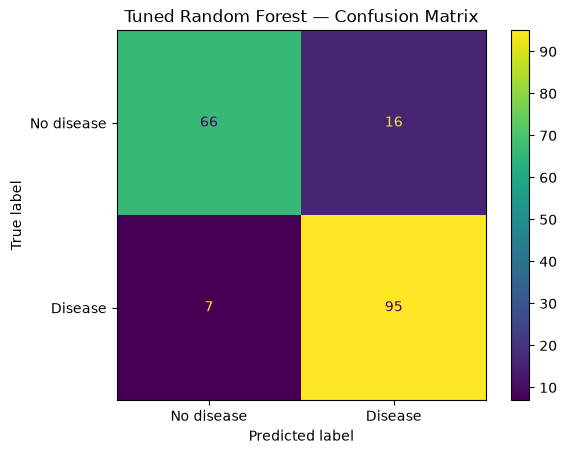

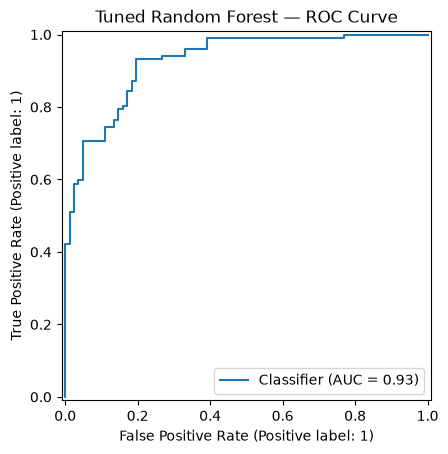

In [12]:
best_model = best_models["Random Forest"]
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= 0.50).astype(int)

final_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Balanced accuracy": balanced_accuracy_score(y_test, test_predictions)
}]).T.rename(columns={0: "Score"})

display(final_metrics.round(4))
print(classification_report(
    y_test, test_predictions, target_names=["No disease", "Disease"], digits=4
))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=["No disease", "Disease"]
)
plt.title("Tuned Random Forest — Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.title("Tuned Random Forest — ROC Curve")
plt.show()

## 6. Save model and results

The saved pipeline includes preprocessing and the trained estimator. Keep the feature schema consistent when using it for inference.

In [ ]:
joblib.dump(best_model, "heart_disease_uci_random_forest.joblib")
baseline_results.to_csv("baseline_model_results.csv", index=False)
tuned_results.drop(columns=["Best parameters"]).to_csv("tuned_model_results.csv", index=False)

print("Saved: heart_disease_uci_random_forest.joblib")
print("Saved: baseline_model_results.csv")
print("Saved: tuned_model_results.csv")

Saved: heart_disease_uci_random_forest.joblib
Saved: baseline_model_results.csv
Saved: tuned_model_results.csv


: 

## Interpretation and limitations

- A binary target is derived from the original 0–4 `num` field; this discards disease severity information.
- The dataset combines records from multiple source datasets and contains substantial missingness in `ca`, `thal`, and `slope`.
- The results depend on the random split and model search; report the split, preprocessing, metrics and uncertainty in any paper.
- Do not claim clinical readiness from this experiment. External validation, calibration, subgroup analysis, and a careful review of source-specific differences are needed.
- The `restecg` field is a categorical ECG interpretation, not a raw ECG waveform. This dataset cannot by itself train a CNN–BiLSTM waveform model.